# Contrastive losses: triplet, hard mining, and InfoNCE

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/2_models/02_contrastive_losses.ipynb) &nbsp; Guide note: [guide-contrastive-learning](https://www.matthewwnuk.com/guide-contrastive-learning.html)

A contrastive loss is told only which items belong together. This notebook trains the same small network
three ways on handwritten digits and compares how well each embedding retrieves images of the same digit.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, te = idx[:1300], idx[1300:]

def net(dim): return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, dim))

@torch.no_grad()
def recall_at_1(f):
    """How often is an image's nearest neighbour (other than itself) the same digit?"""
    e = F.normalize(f(X[te]), dim=-1); s = e @ e.T; s.fill_diagonal_(-9); return (y[te][s.argmax(1)] == y[te]).float().mean().item() * 100

## The three losses

All three work on a batch of embeddings and their labels.

- **Triplet, random negatives.** For each anchor pick one positive and one negative at random.
  The loss is zero once the negative is further away than the positive by a margin.
- **Triplet, hardest in the batch.** Pick the furthest positive and the closest negative.
- **InfoNCE.** Treat each anchor as a classification over the whole batch, where the correct answers are
  the items with the same label.

In [3]:
def triplet_random(e, lab, margin=0.2):
    e = F.normalize(e, dim=-1); dist = torch.cdist(e, e); same = lab[:, None] == lab[None, :]; eye = torch.eye(len(lab), dtype=torch.bool); a = torch.arange(len(lab))
    pos = torch.multinomial((same & ~eye).float() + 1e-9, 1).squeeze(1); neg = torch.multinomial((~same).float() + 1e-9, 1).squeeze(1)
    return F.relu(dist[a, pos] - dist[a, neg] + margin).mean()

def triplet_hard(e, lab, margin=0.2):
    e = F.normalize(e, dim=-1); dist = torch.cdist(e, e); same = lab[:, None] == lab[None, :]; eye = torch.eye(len(lab), dtype=torch.bool)
    hardest_pos = (dist * (same & ~eye)).max(1).values; hardest_neg = (dist + 9 * same).min(1).values
    return F.relu(hardest_pos - hardest_neg + margin).mean()

def info_nce(e, lab, temperature=0.1):
    e = F.normalize(e, dim=-1); eye = torch.eye(len(lab), dtype=torch.bool); pos = (lab[:, None] == lab[None, :]) & ~eye
    log_prob = (e @ e.T / temperature).masked_fill(eye, -1e9).log_softmax(1)
    return -((log_prob * pos).sum(1) / pos.sum(1).clamp(min=1)).mean()

def train(loss_fn, dim=16, epochs=20, seed=0, **kw):
    torch.manual_seed(seed); f = net(dim); opt = torch.optim.Adam(f.parameters(), 1e-3); curve = [recall_at_1(f)]
    for ep in range(epochs):
        perm = tr[torch.randperm(len(tr))]
        for i in range(0, len(perm) - 63, 64):
            b = perm[i:i + 64]; loss = loss_fn(f(X[b]), y[b], **kw); opt.zero_grad(); loss.backward(); opt.step()
        curve.append(recall_at_1(f))
    return f, curve

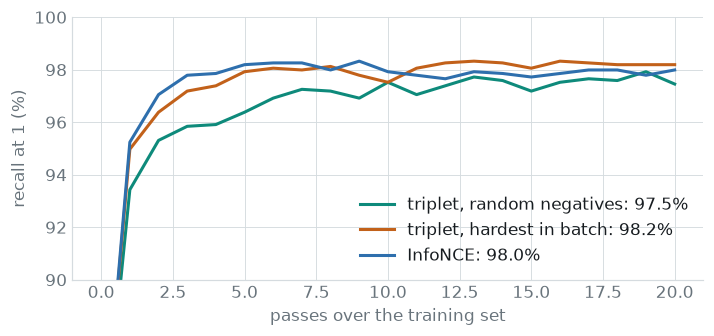

In [4]:
plt.figure(figsize=(7.4, 3.1))
for name, fn in (("triplet, random negatives", triplet_random), ("triplet, hardest in batch", triplet_hard), ("InfoNCE", info_nce)):
    c = np.mean([train(fn, seed=s)[1] for s in range(3)], 0); plt.plot(c, label=f"{name}: {c[-1]:.1f}%")
plt.ylim(90, 100); plt.xlabel("passes over the training set"); plt.ylabel("recall at 1 (%)"); plt.legend(); plt.show()

Choosing negatives matters: the hardest ones in the batch teach more than random ones, most of which
already satisfy the margin and contribute nothing. Contrasting against the whole batch uses every
negative with no mining at all.

## What the loss does to the space

Train with a two-dimensional embedding so that it can be drawn.

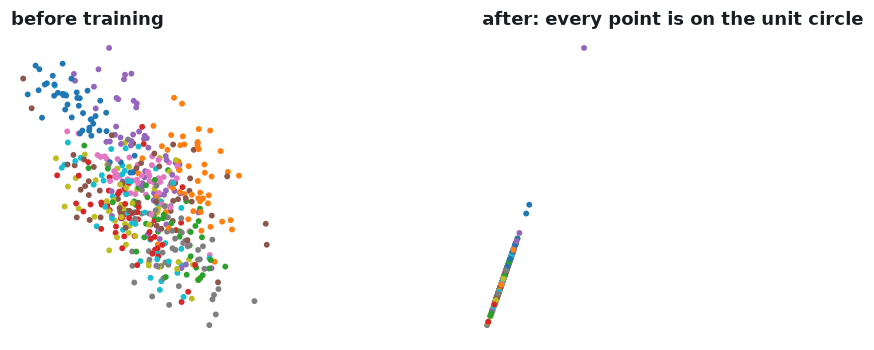

In [5]:
torch.manual_seed(0); f0 = net(2)
with torch.no_grad(): before = f0(X[te]).numpy()
f2, _ = train(triplet_hard, dim=2, epochs=60, margin=0.5)
with torch.no_grad(): after = F.normalize(f2(X[te]), dim=-1).numpy()
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.6))
for a, E, t in zip(ax, (before, after), ("before training", "after: every point is on the unit circle")):
    a.scatter(E[:, 0], E[:, 1], c=y[te], cmap="tab10", s=8); a.set_title(t); style.bare(a); a.set_aspect("equal")
plt.show()

## Temperature

The temperature in InfoNCE sets how sharply the loss concentrates on the most confusing negatives.

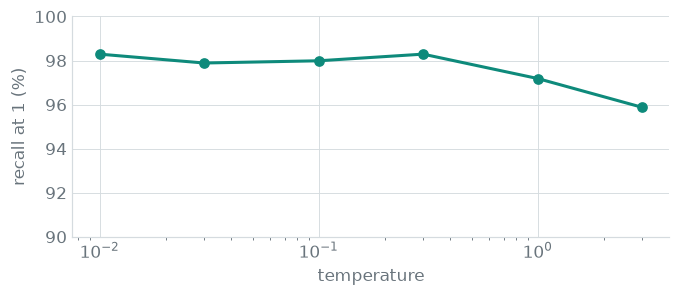

{0.01: 98.3, 0.03: 97.9, 0.1: 98.0, 0.3: 98.3, 1.0: 97.2, 3.0: 95.9}


In [6]:
temps = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]; r = [np.mean([train(info_nce, epochs=10, seed=s, temperature=t)[1][-1] for s in range(2)]) for t in temps]
plt.figure(figsize=(7, 2.6)); plt.plot(temps, r, marker="o"); plt.xscale("log"); plt.xlabel("temperature"); plt.ylabel("recall at 1 (%)"); plt.ylim(90, 100); plt.show()
print({t: round(float(v), 1) for t, v in zip(temps, r)})

On a problem this easy, temperature barely matters. Its reputation comes from large-scale training,
where the supply of hard negatives in a batch is what limits learning.

## Things to try

- Shrink the batch to 8. Which loss suffers most?
- Give 20% of the training labels a random wrong value. Which loss is most robust?
- Train on digits 0 to 7 only and test retrieval on 8 and 9. Does the embedding transfer to unseen classes?